Clustering Dives into Coral Communities
---

Staged work for issue #9, alongside `notebooks/taxon_clustering.ipynb`. That notebook clusters whole survey events by which coral families were present, and its labels are the ones the exploration and results notebooks use. This notebook tries a different set of choices on the same question, and its last section compares the two. The goal is to group places on the seafloor into community types based on which corals and sponges live there together. A single record only says that one animal was seen at one spot, so it cannot describe a community on its own. Instead, records are pooled into sampling units (one dive, split into depth bands when the dive covered a wide depth range), each unit becomes a profile of how abundant each taxon was, and those profiles are clustered.

Four clustering methods from the proposal are tuned and compared side by side: k-means, Gaussian mixture models, DBSCAN and mean-shift. The chosen labels are saved to `data/processed/` so the two approaches can be compared.

Inputs: `data/processed/se_coral_records_cleaned.parquet` from `clean.ipynb`.

In [1]:
import time

import numpy as np
import pandas as pd
from sklearn.cluster import DBSCAN, KMeans, MeanShift, estimate_bandwidth
from sklearn.decomposition import PCA
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score, silhouette_score
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors
from scipy.stats import chi2_contingency

from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt

DATA_DIR = Path("../../data")
FIG_DIR = Path("../../figures")
FIG_DIR.mkdir(exist_ok=True)

# Shared palette so every figure (and the poster) uses the same colors.
# Categorical slots are used in this fixed order, never cycled.
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_BLUE = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
MUTED_GRAY = "#c3c2b7"
INK = "#0b0b0b"
INK_2 = "#52514e"
INK_MUTED = "#898781"
GRID = "#e1e0d9"
LAND = "#e9e8e3"

mpl.rcParams.update({
    "figure.dpi": 110,
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "savefig.facecolor": "#fcfcfb",
    "savefig.dpi": 300,
    "font.family": ["Segoe UI", "DejaVu Sans", "sans-serif"],
    "font.size": 10,
    "text.color": INK,
    "axes.labelcolor": INK_2,
    "axes.edgecolor": MUTED_GRAY,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "xtick.color": INK_MUTED,
    "ytick.color": INK_MUTED,
    "xtick.labelcolor": INK_2,
    "ytick.labelcolor": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2,
    "svg.fonttype": "none",
})


def save(fig, name: str) -> None:
    """Save a figure as SVG (vector, for the poster) next to the other project figures."""
    fig.savefig(FIG_DIR / f"{name}.svg", bbox_inches="tight")

RANDOM_STATE = 0

## Settings

Every threshold used to build the sampling units is defined here so it can be changed and the notebook rerun. The reasoning for each one is given where it is used.

In [2]:
BAND_M = 100  # depth band height within a dive, in meters
MIN_RECORDS = 10  # minimum coral/sponge records for a sampling unit to describe a community
MIN_UNITS_PER_TAXON = 5  # drop taxa seen in fewer sampling units than this
PCA_VARIANCE = 0.70  # share of variance the PCA input to the clustering must keep

## Choosing which records describe a community

Several filters are applied before building profiles. Fish are removed because they move between habitats and the project is about the corals and sponges that form the seafloor community. Records that are only physical specimens are removed, because collecting is selective: a team brings up the particular animals it is studying, not a sample of everything on the seafloor. In this data one program's records are entirely specimens of two target octocorals (*Muricea* and *Swiftia exserta*), which would otherwise form a "community" made of whatever was collected. Video and still-image observations record everything in view, so they are kept, including those that were also collected. Records not gathered by ROV are removed: there are only a few dozen dredge and submersible records, and mixing collection methods would let the method, rather than the animals, separate dives. Records with location accuracy coarser than 50 m are removed so every record can be trusted to belong to its dive and depth. Finally, records not identified to order cannot be placed in a profile, records without a depth cannot be assigned to a depth band, and a few dozen records with no `EventID` cannot be assigned to a dive.

In [3]:
records = pd.read_parquet(DATA_DIR / "processed" / "se_coral_records_cleaned.parquet")
n_start = len(records)

accuracy_m = pd.to_numeric(records["loc_accuracy"].str.removesuffix("m"), errors="coerce")
steps = {
    "Corals and sponges only": records["phylum"].isin(["Cnidaria", "Porifera"]),
    "Observed, not only collected": records["record_type"].ne("specimen"),
    "Collected by ROV": records["sampling_equipment"].eq("ROV"),
    "Location accurate to 50 m": accuracy_m.le(50),
    "Identified to order": records["order"].notna(),
    "Depth recorded": records["depth"].notna(),
    "Assigned to a dive": records["event_id"].notna(),
}
for name, mask in steps.items():
    before = len(records)
    records = records[mask.loc[records.index]]
    print(f"{name:32} kept {len(records):>6,} of {before:>6,}")

print(f"\n{len(records):,} of {n_start:,} records remain")

Corals and sponges only          kept 60,546 of 71,499
Observed, not only collected     kept 60,073 of 60,546
Collected by ROV                 kept 60,073 of 60,073
Location accurate to 50 m        kept 60,073 of 60,073
Identified to order              kept 60,073 of 60,073
Depth recorded                   kept 60,073 of 60,073
Assigned to a dive               kept 60,073 of 60,073

60,073 of 71,499 records remain


## Abundance

Abundance comes from `IndividualCount`. A record with a missing or zero count still means at least one animal was seen, so those counts are set to 1.

In [4]:
records["weight"] = records["count"].fillna(1).clip(lower=1)

## Building sampling units

Most dives stay within a narrow depth range, but a few start in shallow water and descend hundreds of meters, crossing very different habitats. Treating such a dive as a single sample would blend several communities into one profile. Each dive is therefore split into bands of `BAND_M` meters measured from the shallowest record on that dive. A dive that stays within 100 m is one unit, and longer dives become several.

Units with fewer than `MIN_RECORDS` records are dropped, because a handful of sightings is not enough to describe which taxa live together.

In [5]:
dive_top = records.groupby("event_id")["depth"].transform("min")
records["band"] = ((records["depth"] - dive_top) // BAND_M).astype(int)
records["unit_id"] = records["event_id"] + "_b" + records["band"].astype(str)

unit_sizes = records.groupby("unit_id").size()
keep = unit_sizes[unit_sizes >= MIN_RECORDS].index
print(f"{records['event_id'].nunique()} dives -> {len(unit_sizes)} units, "
      f"{len(keep)} with at least {MIN_RECORDS} records")
records = records[records["unit_id"].isin(keep)]

236 dives -> 320 units, 263 with at least 10 records


Each unit also gets a summary of where and when it was collected. None of these are used to form the clusters. They are kept to describe the communities afterwards and as the environmental features a later prediction stage would use.

In [6]:
units = records.groupby("unit_id").agg(
    event_id=("event_id", "first"),
    survey_id=("survey_id", "first"),
    region=("large_marine_ecosystem", "first"),
    data_provider=("data_provider", lambda s: s.mode().iloc[0]),
    obs_date=("obs_date", "min"),
    lat=("lat", "mean"),
    lon=("lon", "mean"),
    depth=("depth", "median"),
    depth_min=("depth", "min"),
    depth_max=("depth", "max"),
    temp=("temp", "median"),
    salinity=("salinity", "median"),
    oxygen=("oxygen", "median"),
    records=("catalog_num", "size"),
    individuals=("weight", "sum"),
    share_no_family=("family", lambda s: s.isna().mean()),
)
units.describe().round(1).T

,count,mean,min,25%,50%,75%,max,std
obs_date,263,2020-03-18 15:52:41.977186,2018-04-19 00:00:00,2018-07-06 00:00:00,2019-07-03 00:00:00,2022-07-04 00:00:00,2022-07-12 00:00:00,NaN
lat,263.0,25.3,17.6,18.0,28.1,29.4,35.1,5.4
lon,263.0,-79.6,-92.9,-87.6,-86.7,-66.8,-64.6,10.3
depth,263.0,369.2,53.0,81.0,102.0,306.0,3000.0,600.9
depth_min,263.0,352.1,50.0,65.0,92.0,303.0,2993.0,597.8
depth_max,263.0,394.8,55.0,86.5,140.0,343.5,3000.0,608.1
temp,163.0,15.2,3.8,8.0,18.6,21.5,23.1,6.9
salinity,163.0,35.9,34.6,35.0,36.4,36.5,36.6,0.7
oxygen,67.0,4.3,2.7,3.3,4.4,4.9,7.0,1.2
records,263.0,227.6,10.0,39.0,103.0,273.5,3006.0,357.0


## Community profiles

The profile of a unit is the share of its individuals that belong to each taxon. Using shares rather than raw counts matters here because effort varies so much: one unit can have twenty records and another two thousand, and raw counts would mostly separate busy dives from quiet ones.

Taxa found in fewer than `MIN_UNITS_PER_TAXON` units are dropped, since a taxon seen once or twice cannot define a recurring community and only adds noise.

Shares are then passed through the Hellinger transform (the square root of each share). This is the standard way to prepare community composition for methods based on Euclidean distance, like k-means. Without it, two units that both lack many rare taxa look similar simply because of the shared zeros, and one very abundant taxon dominates every distance. The square root shrinks the influence of the dominant taxa so that the presence of less common ones still counts.

In [7]:
def build_profiles(taxon: pd.Series) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    """Return (abundance, shares, Hellinger profiles) per unit for the given taxon labels."""
    labeled = records.assign(taxon=taxon).dropna(subset=["taxon"])
    abundance = labeled.pivot_table(index="unit_id", columns="taxon", values="weight", aggfunc="sum", fill_value=0)
    abundance = abundance.loc[:, (abundance > 0).sum() >= MIN_UNITS_PER_TAXON]
    abundance = abundance[abundance.sum(axis=1) > 0]
    shares = abundance.div(abundance.sum(axis=1), axis=0)
    return abundance, shares, np.sqrt(shares)


def to_pca(profiles: pd.DataFrame) -> np.ndarray:
    """Project profiles onto the fewest principal components that keep PCA_VARIANCE of the variance."""
    cum_var = np.cumsum(PCA(random_state=RANDOM_STATE).fit(profiles).explained_variance_ratio_)
    n = int(np.searchsorted(cum_var, PCA_VARIANCE) + 1)
    return PCA(n_components=n, random_state=RANDOM_STATE).fit_transform(profiles)


def cramers_v(a: pd.Series, b: pd.Series) -> float:
    """Association between two categorical variables, from 0 (unrelated) to 1 (one determines the other)."""
    table = pd.crosstab(a, b)
    chi2 = chi2_contingency(table)[0]
    return float(np.sqrt(chi2 / (table.to_numpy().sum() * (min(table.shape) - 1))))

## Choosing the taxonomic level

The proposal planned to describe communities by family. Not every record is identified to family, though: about a fifth stop at order, and how often that happens depends heavily on who did the identification. That raises a real risk. If one data provider routinely names families that another lumps together, their dives will look like different communities even when the same animals are present, and the clustering will rediscover the providers instead of the biology.

To test this, profiles are built three ways: by family, keeping records without a family under their order (for example, "Antipatharia (family unknown)"); by family, dropping records without a family; and by order. Each is clustered with k-means across a range of k, and two things are measured. The silhouette score says how distinct the clusters are, and Cramér's V between the clusters and the data provider says how much the clusters simply track who collected the data (0 means unrelated, 1 means the provider fully determines the cluster). The PCA step used here is explained in the next section.

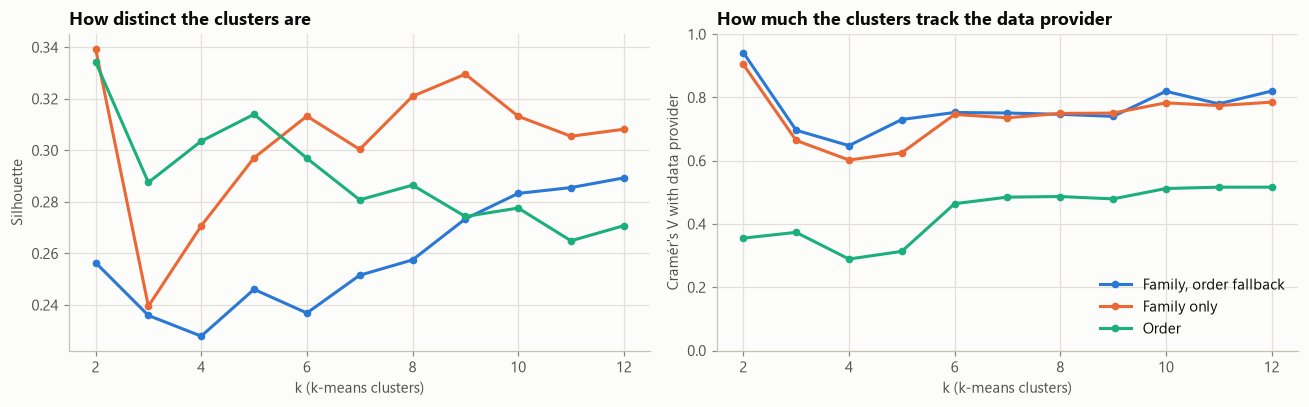

,units,taxa,silhouette,provider_v
scheme,,,,
Family only,262.0,46.0,0.31,0.75
"Family, order fallback",263.0,52.0,0.26,0.75
Order,263.0,19.0,0.29,0.48


In [8]:
schemes = {
    "Family, order fallback": records["family"].fillna(records["order"] + " (family unknown)"),
    "Family only": records["family"],
    "Order": records["order"],
}

rows = []
for name, taxon in schemes.items():
    _, _, profiles = build_profiles(taxon)
    X_scheme = to_pca(profiles)
    provider = units.loc[profiles.index, "data_provider"]
    for k in range(2, 13):
        labels = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit_predict(X_scheme)
        rows.append({"scheme": name, "k": k, "units": len(profiles), "taxa": profiles.shape[1],
                     "silhouette": silhouette_score(X_scheme, labels),
                     "provider_v": cramers_v(pd.Series(labels, index=profiles.index), provider)})
scheme_scores = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharex=True)
for i, name in enumerate(schemes):
    sub = scheme_scores[scheme_scores["scheme"] == name]
    axes[0].plot(sub["k"], sub["silhouette"], color=SERIES[i], marker="o", markersize=4, label=name)
    axes[1].plot(sub["k"], sub["provider_v"], color=SERIES[i], marker="o", markersize=4, label=name)
axes[0].set(xlabel="k (k-means clusters)", ylabel="Silhouette", title="How distinct the clusters are")
axes[1].set(xlabel="k (k-means clusters)", ylabel="Cramér's V with data provider", ylim=(0, 1),
            title="How much the clusters track the data provider")
axes[1].legend(loc="lower right")
fig.tight_layout()
save(fig, "cluster_taxonomic_level")
plt.show()

scheme_scores.groupby("scheme")[["units", "taxa", "silhouette", "provider_v"]].median().round(2)

The comparison makes the choice clear. Both family-level schemes produce clusters that track the data provider closely, with a median Cramér's V around 0.75 and above 0.9 for the very first split at k = 2. In other words, the biggest difference the clustering finds between family-level profiles is who identified the animals. Order-level profiles give clusters about as distinct as the family-level ones (a median silhouette of about 0.29) while cutting the provider association roughly in half, and to about 0.3 at the small values of k where a community typology is most useful.

The cost is resolution. Nineteen orders replace about fifty families, so communities are described in broader strokes, black corals against stony corals rather than particular black coral families. Since the goal is to find communities that are real enough for environmental conditions to predict, comparability across providers matters more here than detail, and the rest of the analysis uses order-level profiles. Family-level communities would be worth revisiting with data from a single provider, or after harmonizing identifications across providers with help from our domain lead.

In [9]:
abundance, shares, hellinger = build_profiles(records["order"])
units = units.loc[hellinger.index]
units["orders_present"] = (abundance > 0).sum(axis=1)

print(f"{hellinger.shape[0]} units x {hellinger.shape[1]} orders")

263 units x 19 orders


## Reducing dimensions with PCA

Even at the order level the profiles have about twenty dimensions, many of them zero in any given unit. Density-based methods (DBSCAN and mean-shift) break down in that setting, because in high dimensions almost every point is far from every other point. Principal component analysis compresses the profiles into the few directions that carry most of the variation. All four methods get the same PCA input so their results can be compared fairly.

The number of components is the smallest that keeps `PCA_VARIANCE` of the variance. The clustering is unsupervised and has no labels to leak, so the PCA is fit on all units.

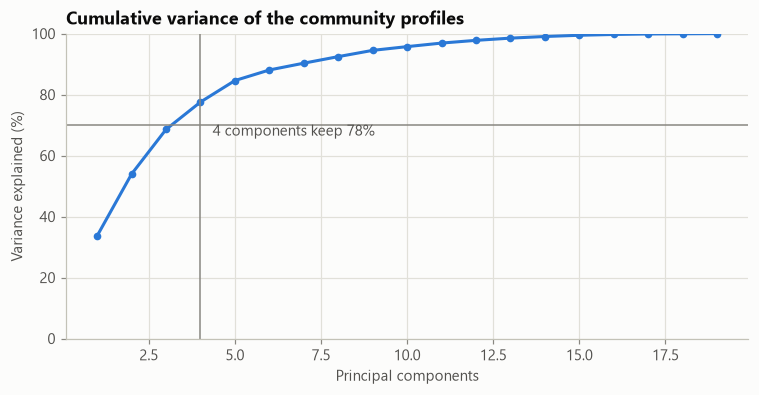

Clustering input: 263 units x 4 features


In [10]:
pca_full = PCA(random_state=RANDOM_STATE).fit(hellinger)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)
n_components = int(np.searchsorted(cum_var, PCA_VARIANCE) + 1)

pca = PCA(n_components=n_components, random_state=RANDOM_STATE)
X = pca.fit_transform(hellinger)

fig, ax = plt.subplots(figsize=(8, 3.6))
shown = min(len(cum_var), 40)
ax.plot(range(1, shown + 1), cum_var[:shown] * 100, color=SERIES[0], marker="o", markersize=4)
ax.axhline(PCA_VARIANCE * 100, color=INK_MUTED, linewidth=1)
ax.axvline(n_components, color=INK_MUTED, linewidth=1)
ax.annotate(f"{n_components} components keep {cum_var[n_components - 1]:.0%}",
            (n_components, cum_var[n_components - 1] * 100), xytext=(8, -22),
            textcoords="offset points", color=INK_2)
ax.set_xlabel("Principal components")
ax.set_ylabel("Variance explained (%)")
ax.set_ylim(0, 100)
ax.set_title("Cumulative variance of the community profiles")
save(fig, "cluster_pca_variance")
plt.show()

print(f"Clustering input: {X.shape[0]} units x {X.shape[1]} features")

## Tuning each method

Each method has a setting that controls how many clusters it finds, and each is tuned with the criterion that suits it:

- **k-means** needs the number of clusters, k. It is tried from 2 to 12 and judged by the silhouette score, which compares how close each unit is to its own cluster against how close it is to the nearest other cluster (from -1 to 1, higher is better).
- **Gaussian mixture models** also need a number of components and are judged by BIC, which rewards fitting the data but penalizes extra components. Both full and diagonal covariance are tried.
- **DBSCAN** finds clusters as dense regions and labels isolated units as noise. Its radius `eps` is tried across the range of distances from each unit to its 5th nearest neighbor.
- **Mean-shift** finds the peaks of the density, and its bandwidth controls how smooth that density is. Bandwidths are estimated from a range of quantiles of the pairwise distances.

All candidates are scored with the same three measures so they can be compared: silhouette (higher is better), Davies-Bouldin (lower is better; the average similarity between each cluster and the one most like it) and Calinski-Harabasz (higher is better; the ratio of spread between clusters to spread within them). Noise points are left out of the scores but reported separately.

In [11]:
def score(labels: np.ndarray, X: np.ndarray, seconds: float, **params) -> dict:
    clustered = labels != -1
    n_clusters = len(set(labels[clustered]))
    row = {
        **params,
        "n_clusters": n_clusters,
        "noise_share": 1 - clustered.mean(),
        "smallest_cluster": int(np.bincount(labels[clustered]).min()) if n_clusters else 0,
        "silhouette": np.nan,
        "davies_bouldin": np.nan,
        "calinski_harabasz": np.nan,
        "fit_seconds": seconds,
        "n_features": X.shape[1],
    }
    if n_clusters >= 2:
        row["silhouette"] = silhouette_score(X[clustered], labels[clustered])
        row["davies_bouldin"] = davies_bouldin_score(X[clustered], labels[clustered])
        row["calinski_harabasz"] = calinski_harabasz_score(X[clustered], labels[clustered])
    return row


def timed_fit(model, X):
    start = time.perf_counter()
    labels = model.fit_predict(X)
    return labels, time.perf_counter() - start

In [12]:
candidates = []
labels_by_candidate = {}

for k in range(2, 13):
    labels, secs = timed_fit(KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE), X)
    candidates.append(score(labels, X, secs, method="k-means", param=f"k={k}"))
    labels_by_candidate[("k-means", f"k={k}")] = labels

for cov in ("full", "diag"):
    for k in range(2, 13):
        gmm = GaussianMixture(n_components=k, covariance_type=cov, n_init=5, random_state=RANDOM_STATE)
        labels, secs = timed_fit(gmm, X)
        row = score(labels, X, secs, method="Gaussian mixture", param=f"{cov}, k={k}")
        row["bic"] = gmm.bic(X)
        candidates.append(row)
        labels_by_candidate[("Gaussian mixture", row["param"])] = labels

knn_dist = np.sort(NearestNeighbors(n_neighbors=5).fit(X).kneighbors(X)[0][:, -1])
for q in np.arange(0.50, 0.96, 0.05):
    eps = float(np.quantile(knn_dist, q))
    labels, secs = timed_fit(DBSCAN(eps=eps, min_samples=5), X)
    param = f"eps={eps:.3f} (q{q:.2f})"
    candidates.append(score(labels, X, secs, method="DBSCAN", param=param))
    labels_by_candidate[("DBSCAN", param)] = labels

for q in np.arange(0.10, 0.51, 0.05):
    bw = estimate_bandwidth(X, quantile=q, random_state=RANDOM_STATE)
    labels, secs = timed_fit(MeanShift(bandwidth=bw, bin_seeding=True), X)
    param = f"bandwidth={bw:.3f} (q{q:.2f})"
    candidates.append(score(labels, X, secs, method="Mean-shift", param=param))
    labels_by_candidate[("Mean-shift", param)] = labels

candidates = pd.DataFrame(candidates)
candidates.round(3)

,method,param,n_clusters,noise_share,smallest_cluster,silhouette,davies_bouldin,calinski_harabasz,fit_seconds,n_features,bic
0,k-means,k=2,2,0.000,82,0.334,1.191,132.430,0.063,4,NaN
1,k-means,k=3,3,0.000,67,0.288,1.317,122.042,0.088,4,NaN
2,k-means,k=4,4,0.000,56,0.304,1.222,118.670,0.090,4,NaN
3,k-means,k=5,5,0.000,23,0.314,1.100,110.350,0.093,4,NaN
4,k-means,k=6,6,0.000,23,0.297,1.104,106.844,0.092,4,NaN
5,k-means,k=7,7,0.000,20,0.281,1.101,101.932,0.098,4,NaN
6,k-means,k=8,8,0.000,18,0.286,1.053,98.444,0.106,4,NaN
7,k-means,k=9,9,0.000,15,0.274,1.117,95.728,0.121,4,NaN
8,k-means,k=10,10,0.000,17,0.278,1.079,92.946,0.090,4,NaN
9,k-means,k=11,11,0.000,12,0.265,1.079,91.803,0.096,4,NaN


The tuning curves below show how each method's score responds to its setting.

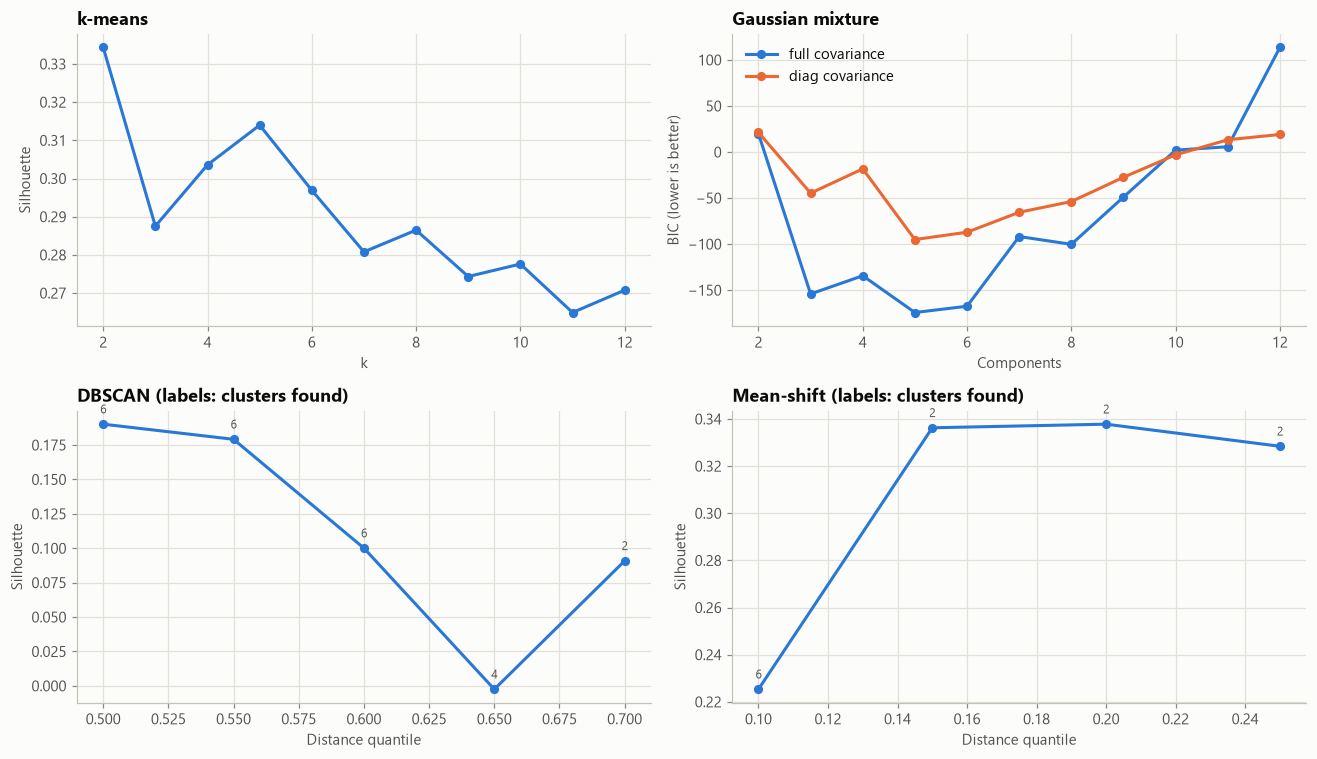

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))

km = candidates[candidates["method"] == "k-means"]
axes[0, 0].plot(km["n_clusters"], km["silhouette"], color=SERIES[0], marker="o", markersize=5)
axes[0, 0].set(xlabel="k", ylabel="Silhouette", title="k-means")

gm = candidates[candidates["method"] == "Gaussian mixture"]
for i, cov in enumerate(("full", "diag")):
    sub = gm[gm["param"].str.startswith(cov)]
    k = sub["param"].str.extract(r"k=(\d+)")[0].astype(int)
    axes[0, 1].plot(k, sub["bic"], color=SERIES[i], marker="o", markersize=5, label=f"{cov} covariance")
axes[0, 1].legend()
axes[0, 1].set(xlabel="Components", ylabel="BIC (lower is better)", title="Gaussian mixture")

for ax, method in ((axes[1, 0], "DBSCAN"), (axes[1, 1], "Mean-shift")):
    sub = candidates[candidates["method"] == method]
    q = sub["param"].str.extract(r"q([\d.]+)")[0].astype(float)
    ax.plot(q, sub["silhouette"], color=SERIES[0], marker="o", markersize=5)
    for x, y, n in zip(q, sub["silhouette"], sub["n_clusters"]):
        if np.isfinite(y):
            ax.annotate(f"{n}", (x, y), xytext=(0, 7), textcoords="offset points",
                        ha="center", color=INK_2, fontsize=8)
    ax.set(xlabel="Distance quantile", ylabel="Silhouette",
           title=f"{method} (labels: clusters found)")

fig.tight_layout()
save(fig, "cluster_tuning")
plt.show()

## Picking each method's best setting

Raw silhouette tends to favor the fewest, broadest clusters, and a split into two groups says little about community types. Each method's winner is therefore chosen among settings that give at least three clusters, label at most a quarter of units as noise and leave no cluster with fewer than five units (too small to describe or evaluate). Among those, k-means, DBSCAN and mean-shift take the highest silhouette, and the Gaussian mixture takes the lowest BIC, which is the criterion that model is designed around.

In [14]:
MIN_CLUSTERS, MAX_NOISE, MIN_CLUSTER_SIZE = 3, 0.25, 5

eligible = candidates[
    (candidates["n_clusters"] >= MIN_CLUSTERS)
    & (candidates["noise_share"] <= MAX_NOISE)
    & (candidates["smallest_cluster"] >= MIN_CLUSTER_SIZE)
]

winners = []
for method, group in eligible.groupby("method", sort=False):
    pick = group["bic"].idxmin() if method == "Gaussian mixture" else group["silhouette"].idxmax()
    winners.append(candidates.loc[pick])
for method in set(candidates["method"]) - set(eligible["method"]):
    print(f"{method}: no setting met the constraints")

comparison = pd.DataFrame(winners).set_index("method")
comparison[["param", "n_clusters", "noise_share", "smallest_cluster", "silhouette",
            "davies_bouldin", "calinski_harabasz", "fit_seconds", "n_features"]].round(3)

,param,n_clusters,noise_share,smallest_cluster,silhouette,davies_bouldin,calinski_harabasz,fit_seconds,n_features
method,,,,,,,,,
k-means,k=5,5,0.000,23,0.314,1.100,110.350,0.093,4
Gaussian mixture,"full, k=5",5,0.000,25,0.142,1.438,66.984,0.235,4
DBSCAN,eps=0.213 (q0.65),4,0.171,5,-0.002,1.129,10.153,0.003,4
Mean-shift,bandwidth=0.362 (q0.10),6,0.000,7,0.225,1.349,70.826,0.358,4


## Comparing the methods side by side

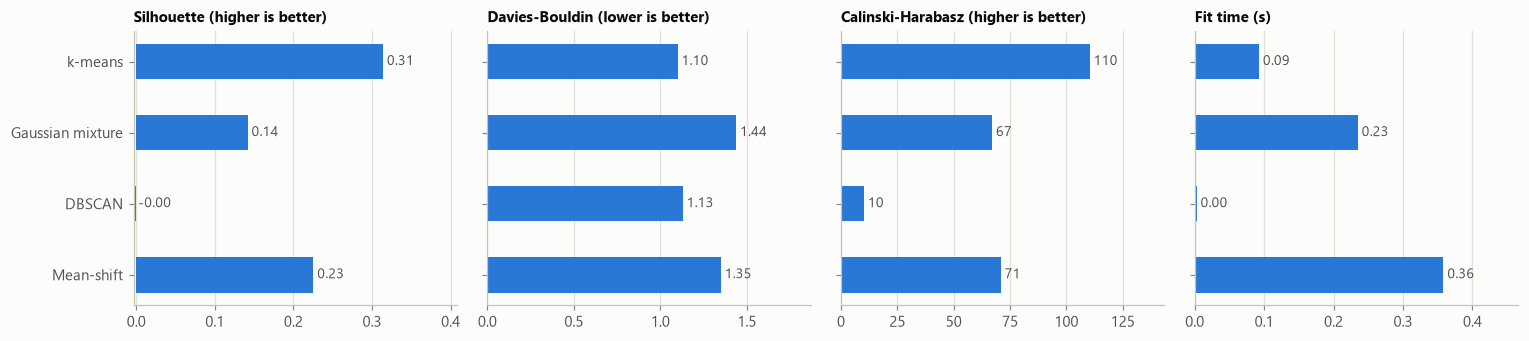

In [15]:
metrics = [("silhouette", "Silhouette (higher is better)"),
           ("davies_bouldin", "Davies-Bouldin (lower is better)"),
           ("calinski_harabasz", "Calinski-Harabasz (higher is better)"),
           ("fit_seconds", "Fit time (s)")]

fig, axes = plt.subplots(1, 4, figsize=(14, 3.2), sharey=True)
for ax, (col, title) in zip(axes, metrics):
    values = comparison[col]
    ax.barh(comparison.index, values, color=SERIES[0], height=0.5)
    for y, v in enumerate(values):
        ax.text(v, y, f" {v:.2f}" if col != "calinski_harabasz" else f" {v:.0f}",
                va="center", color=INK_2, fontsize=9)
    ax.set_xlim(min(0, values.min() * 1.3), values.max() * 1.3)
    ax.set_title(title, fontsize=10)
    ax.grid(axis="y", visible=False)
axes[0].invert_yaxis()
fig.tight_layout()
save(fig, "cluster_method_comparison")
plt.show()

## Choosing the final model

Every sampling unit needs a community label to be mapped and, later, to serve as a prediction target, so the final model must assign at least 90% of units to a cluster. Among the winners that do, the one with the best silhouette is chosen, since that is the one measure all four methods are judged on and it directly answers how distinct the communities are.

In [16]:
MAX_FINAL_NOISE = 0.10
final_method = comparison.loc[comparison["noise_share"] <= MAX_FINAL_NOISE, "silhouette"].idxmax()
final_param = comparison.loc[final_method, "param"]
units["community"] = labels_by_candidate[(final_method, final_param)]

print(f"Final model: {final_method} ({final_param})")
units["community"].value_counts().sort_index()

Final model: k-means (k=5)


community
0    64
1    43
2    68
3    23
4    65
Name: count, dtype: int64

## Checking for artifacts of how the data was collected

A cluster could reflect who collected the data rather than which animals live there. Working at the order level removed the worst of this, but providers also surveyed different places: one program worked mostly in deep water and another almost entirely on mesophotic reefs in the Gulf. If a community turned out to be just one provider's dives, it would be hard to tell biology from recording practice.

Cramér's V measures how strongly two categorical variables are associated, from 0 (unrelated) to 1 (one fully determines the other). It is computed between the communities and the data provider, the survey and the region. Some association with survey and region is expected, because surveys target particular habitats. The concern is when association with the provider is very high while composition is otherwise similar.

In [17]:
clustered = units[units["community"] != -1]
association = pd.Series({
    col: cramers_v(clustered["community"], clustered[col])
    for col in ("data_provider", "survey_id", "region")
}, name="cramers_v")
print(association.round(2))

pd.crosstab(clustered["community"], clustered["data_provider"].str.replace("NOAA, ", "", regex=False))

data_provider    0.31
survey_id        0.42
region           0.32
Name: cramers_v, dtype: float64


data_provider,Flower Garden Banks National Marine Sanctuary,Mesophotic Deep Benthic Communities Restoration Project,National Centers for Coastal Ocean Science,Office of Ocean Exploration and Research
community,,,,
0,13,27,18,6
1,4,21,7,11
2,9,5,26,28
3,2,2,12,7
4,0,41,8,16


In [18]:
units.groupby("community")[["depth", "share_no_family"]].median().round(2)

,depth,share_no_family
community,,
0,95.0,0.08
1,82.0,0.11
2,149.0,0.06
3,110.0,0.05
4,102.0,0.25


With order-level profiles the association between communities and data provider is modest (Cramér's V around 0.3), and every community contains dives from several providers. The association with survey and region is in a similar range, which fits surveys that targeted particular habitats better than it fits clusters that are artifacts of recording. One pattern is still worth keeping in mind: the Mesophotic Deep Benthic Communities project contributed the largest share of units and has the highest share of records without a family, especially among stony corals. That does not change order-level profiles, but some communities lean heavily on that one program's dives, which is why any evaluation of these communities should hold out whole areas rather than random units.

## Saving the results

The units with their community labels, the profiles, the PCA coordinates and the model comparison are saved to `data/processed/`.

In [19]:
out = DATA_DIR / "processed"
units.to_parquet(out / "staged_units.parquet")
shares.to_parquet(out / "staged_unit_shares.parquet")
hellinger.to_parquet(out / "staged_unit_hellinger.parquet")
pd.DataFrame(X, index=units.index, columns=[f"PC{i + 1}" for i in range(X.shape[1])]).to_parquet(
    out / "staged_unit_pca.parquet"
)
candidates.to_csv(out / "staged_cluster_candidates.csv", index=False)
comparison.to_csv(out / "staged_cluster_comparison.csv")
print(f"Saved {len(units)} units to {out}")

Saved 263 units to ..\..\data\processed


## Comparison with the event-level family clustering

`taxon_clustering.ipynb` makes different choices at almost every step: it clusters whole survey events rather than depth bands, uses corals only, keeps collected specimens, and describes each event by which of 43 coral families were present rather than by order-level shares. Its k-means picks two communities. This section lines its labels up against the ones above, using each dive's most common community from this notebook, and checks how strongly each set of labels tracks the data provider and depth. Run `taxon_clustering.ipynb` first.

In [20]:
from sklearn.metrics import adjusted_rand_score

keys = ["survey_id", "event_id"]
events = pd.read_parquet(DATA_DIR / "processed" / "taxon_cluster_events.parquet")
events[keys] = events[keys].astype("string")
dives = units.assign(**{k: units[k].astype("string").str.strip() for k in keys})
dive_community = dives.groupby(keys)["community"].agg(lambda s: s.mode().iat[0]).rename("order_community")
both = events.join(dive_community, on=keys, how="inner")

print(f"{len(both)} of {len(events)} events are also in this notebook's units")
print(f"Adjusted Rand index between the two sets of labels: {adjusted_rand_score(both['cluster'], both['order_community']):.2f}")
pd.crosstab(both["order_community"], both["cluster"]).rename_axis(
    index="This notebook (order level)", columns="taxon_clustering (family presence)")

223 of 275 events are also in this notebook's units
Adjusted Rand index between the two sets of labels: 0.02


taxon_clustering (family presence),0,1
This notebook (order level),,
0,58,5
1,31,8
2,32,16
3,14,3
4,46,10


In [21]:
cleaned = pd.read_parquet(DATA_DIR / "processed" / "se_coral_records_cleaned.parquet", columns=[*keys, "depth"])
event_depth = cleaned.assign(**{k: cleaned[k].astype("string").str.strip() for k in keys}).groupby(keys)["depth"].median()
events["depth"] = events.set_index(keys).index.map(event_depth)
events["provider"] = events["data_providers"].str.split(" | ", regex=False).str[0]

pd.DataFrame({
    "communities": [units["community"].nunique(), events["cluster"].nunique()],
    "cramers_v_provider": [cramers_v(units["community"], units["data_provider"].fillna("?")),
                           cramers_v(events["cluster"], events["provider"].fillna("?"))],
    "units_deeper_than_500m": [(units["depth"] > 500).sum(), (events["depth"] > 500).sum()],
}, index=["This notebook (order level)", "taxon_clustering (family presence)"]).round(2)

,communities,cramers_v_provider,units_deeper_than_500m
This notebook (order level),5,0.31,54
taxon_clustering (family presence),2,0.83,49


In [22]:
deep_units = units[units["depth"] > 500]
print("Providers of units deeper than 500 m:", deep_units["data_provider"].value_counts().to_dict())
print("Communities of units deeper than 500 m:", deep_units["community"].value_counts().sort_index().to_dict())

Providers of units deeper than 500 m: {'NOAA, Office of Ocean Exploration and Research': 54}
Communities of units deeper than 500 m: {0: 2, 1: 10, 2: 24, 3: 4, 4: 14}


The two approaches find almost unrelated structure: the adjusted Rand index is 0.02, where 0 means no more agreement than chance. They are not contradicting each other so much as answering different questions. The family-presence clustering splits the events by depth: a shallow community at a median of about 90 m and a deep one at about 800 m, marked by deep-water families such as bamboo, golden and primnoid corals. The order-level clustering looks across depth instead, because at the order level a deep site and a shallow site can look alike, and each of its five communities contains some of the 54 units deeper than 500 m.

The comparison also shows why neither set of labels can be taken at face value. Every unit deeper than 500 m in this notebook comes from NOAA's Office of Ocean Exploration and Research (in the event-level data, 43 of 49 deep events do, and the rest are Smithsonian collections), so in this dataset deep water and that one program's dives are nearly the same set of samples. The family-presence clustering's depth split therefore tracks the provider closely (Cramér's V 0.83), while the order-level clustering avoids that only by mixing depth zones together (0.31). The project uses the family-presence labels for the exploration and results notebooks, with this caveat stated alongside them. Clustering only the mesophotic events, where four programs overlap, would be the most direct way to find communities that are not tied to who collected them.